In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt


# 1. Load data
df = pd.read_csv('wine.csv')




In [24]:
df.head()
df.info()
df.shape
print(df.head())
print(df.info())
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Wine                  178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic.acid            178 non-null    float64
 3   Ash                   178 non-null    float64
 4   Acl                   178 non-null    float64
 5   Mg                    178 non-null    int64  
 6   Phenols               178 non-null    float64
 7   Flavanoids            178 non-null    float64
 8   Nonflavanoid.phenols  178 non-null    float64
 9   Proanth               178 non-null    float64
 10  Color.int             178 non-null    float64
 11  Hue                   178 non-null    float64
 12  OD                    178 non-null    float64
 13  Proline               178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB
   Wine  Alcohol  Malic.acid   Ash   A

In [25]:
# 2. Separate features and target
X = df.drop("Wine", axis=1)
y = df["Wine"]
print(X)
print(y)

     Alcohol  Malic.acid   Ash   Acl   Mg  Phenols  Flavanoids  \
0      14.23        1.71  2.43  15.6  127     2.80        3.06   
1      13.20        1.78  2.14  11.2  100     2.65        2.76   
2      13.16        2.36  2.67  18.6  101     2.80        3.24   
3      14.37        1.95  2.50  16.8  113     3.85        3.49   
4      13.24        2.59  2.87  21.0  118     2.80        2.69   
..       ...         ...   ...   ...  ...      ...         ...   
173    13.71        5.65  2.45  20.5   95     1.68        0.61   
174    13.40        3.91  2.48  23.0  102     1.80        0.75   
175    13.27        4.28  2.26  20.0  120     1.59        0.69   
176    13.17        2.59  2.37  20.0  120     1.65        0.68   
177    14.13        4.10  2.74  24.5   96     2.05        0.76   

     Nonflavanoid.phenols  Proanth  Color.int   Hue    OD  Proline  
0                    0.28     2.29       5.64  1.04  3.92     1065  
1                    0.26     1.28       4.38  1.05  3.40     1050  


In [26]:
# 3. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [27]:
# 4. Scale data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
# 5. Create KNN model
model = KNeighborsClassifier(n_neighbors=5)
print(model)

KNeighborsClassifier()


In [29]:
# 6. Train model
model.fit(X_train, y_train)


# 7. Predict
y_pred = model.predict(X_test)

print(y_pred)

[1 2 1 1 1 1 3 2 2 3 3 2 3 2 1 3 2 1 3 3 2 3 3 3 3 3 1 2 1 3 1 2 3 2 2 3 2
 2 2 1 3 1 1 1 1 2 2 1 3 1 2 2 3 1]


In [30]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9444444444444444


In [31]:
df.shape

(178, 14)

In [32]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0



Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        18
           2       1.00      0.86      0.92        21
           3       0.83      1.00      0.91        15

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.94        54
weighted avg       0.95      0.94      0.94        54


Confusion Matrix:
[[18  0  0]
 [ 0 18  3]
 [ 0  0 15]]


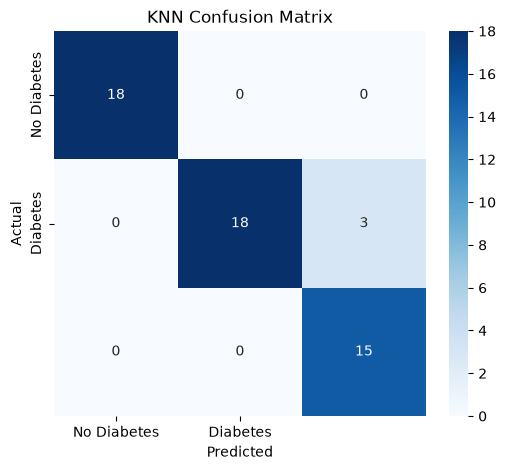

In [33]:
# 9. Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# 10. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# 11. Confusion matrix visualization
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()